# AE 2: Anomaly Detector (Bank Marketing)

**Goal:** find customers who are likely to say **yes** to the term deposit by treating them as *anomalies*.

**Idea:**
1. Train an autoencoder on **"no" customers only**, so it learns what a normal customer looks like.
2. Give it any customer and measure the **reconstruction error**.
3. A high error means the customer does not look like a normal "no" customer, so we flag them as a possible **"yes"**.

**Key outputs:** error distribution for yes vs no, and per-feature reconstruction error.

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Same results every run
keras.utils.set_random_seed(42)

# Colors used in all plots
color_no = "#2a78d6"
color_yes = "#eb6834"

# Load the data

If you are using Google Colab, upload `bank_clean.csv` to the Files panel first.

In [2]:
df = pd.read_csv("bank_clean.csv")

print(df.shape)
df.head()

(41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [3]:
print(df["y"].value_counts())
print("Percentage of yes:", round(df["y"].mean() * 100, 2), "%")

y
0    36537
1     4639
Name: count, dtype: int64
Percentage of yes: 11.27 %


# Prepare the data

* Categorical columns are converted to numbers with one-hot encoding.
* The data is split into **70% train, 15% validation, 15% test**.
* The validation set is used to choose the model and the threshold. The test set is used only once, at the end.

In [4]:
y = df["y"].values

X = pd.get_dummies(df.drop(columns=["y"])).astype("float32")
feature_names = X.columns
x = X.values

print("Number of features after encoding:", x.shape[1])

Number of features after encoding: 63


In [5]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, stratify=y, random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Train: (28823, 63)
Validation: (6176, 63)
Test: (6177, 63)


## Keep "no" customers for training and normalize

The scaler is fitted on the training "no" customers only, so no information comes from the validation or test data.
Values are scaled to 0-1 because the decoder ends with a `sigmoid` layer, the same as the MNIST autoencoder.

In [6]:
# Train only on normal customers
x_train_no = x_train[y_train == 0]

# Normalize
scaler = MinMaxScaler()
x_train_no = scaler.fit_transform(x_train_no)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

# Keep values between 0 and 1
x_val = np.clip(x_val, 0., 1.)
x_test = np.clip(x_test, 0., 1.)

# "No" customers in validation, used to monitor training
x_val_no = x_val[y_val == 0]

print("Training customers (no only):", x_train_no.shape)
print("Validation customers (no only):", x_val_no.shape)

Training customers (no only): (25576, 63)
Validation customers (no only): (5480, 63)


# Build autoencoder

In [7]:
n_features = x_train_no.shape[1]

def build_autoencoder(encoding_dim, hidden_units):
    input_layer = keras.layers.Input(shape=(n_features,))

    # Encoder
    encoded = input_layer
    for units in hidden_units:
        encoded = keras.layers.Dense(units, activation='relu')(encoded)
    encoded = keras.layers.Dense(encoding_dim, activation='relu')(encoded)

    # Decoder
    decoded = encoded
    for units in reversed(hidden_units):
        decoded = keras.layers.Dense(units, activation='relu')(decoded)
    decoded = keras.layers.Dense(n_features, activation='sigmoid')(decoded)

    autoencoder = keras.Model(input_layer, decoded)
    autoencoder.compile(optimizer='adam', loss='mse')
    return autoencoder


# Reconstruction error of each customer
def reconstruction_error(model, data):
    reconstructed = model.predict(data, verbose=0)
    return np.mean((data - reconstructed) ** 2, axis=1)

# Manual hyperparameter tuning

We compare different **latent space sizes** and **numbers of layers**.

The models are compared with **ROC-AUC** on the validation set. It measures how well the error separates yes from no:
0.5 is random and 1.0 is perfect. Accuracy is not useful here because about 89% of customers are "no".

In [8]:
latent_sizes = [4, 8, 16]
hidden_options = [[32], [64, 32]]

results = []

for hidden_units in hidden_options:
    for encoding_dim in latent_sizes:
        keras.utils.set_random_seed(42)

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )

        model = build_autoencoder(encoding_dim, hidden_units)
        history = model.fit(
            x_train_no, x_train_no,
            epochs=60,
            batch_size=256,
            shuffle=True,
            validation_data=(x_val_no, x_val_no),
            callbacks=[early_stop],
            verbose=0
        )

        val_errors = reconstruction_error(model, x_val)
        auc = roc_auc_score(y_val, val_errors)
        pr_auc = average_precision_score(y_val, val_errors)

        results.append({
            "hidden_units": hidden_units,
            "encoding_dim": encoding_dim,
            "epochs": len(history.history["loss"]),
            "val_loss": min(history.history["val_loss"]),
            "ROC_AUC": auc,
            "PR_AUC": pr_auc
        })
        print(f"Hidden {hidden_units}, Latent {encoding_dim} → ROC-AUC: {auc:.4f}")

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
results_df.round(4)

Hidden [32], Latent 4 → ROC-AUC: 0.6797


Hidden [32], Latent 8 → ROC-AUC: 0.6843


Hidden [32], Latent 16 → ROC-AUC: 0.7009


Hidden [64, 32], Latent 4 → ROC-AUC: 0.6940


Hidden [64, 32], Latent 8 → ROC-AUC: 0.6778


Hidden [64, 32], Latent 16 → ROC-AUC: 0.6863


,hidden_units,encoding_dim,epochs,val_loss,ROC_AUC,PR_AUC
0,[32],16,60,0.0086,0.7009,0.2802
1,"[64, 32]",4,60,0.0353,0.6940,0.2658
2,"[64, 32]",16,59,0.0111,0.6863,0.2567
3,[32],8,60,0.0178,0.6843,0.2704
4,[32],4,60,0.0437,0.6797,0.2424
5,"[64, 32]",8,60,0.0146,0.6778,0.2470


In [9]:
best_hidden = results_df.loc[0, "hidden_units"]
best_encoding_dim = int(results_df.loc[0, "encoding_dim"])

print("Best hidden layers:", best_hidden)
print("Best latent size:", best_encoding_dim)

Best hidden layers: [32]
Best latent size: 16


# Start training the best model

In [10]:
keras.utils.set_random_seed(42)

autoencoder = build_autoencoder(best_encoding_dim, best_hidden)
autoencoder.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 63)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 63)             │         2,079 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,199 (20.31 KB)

 Trainable params: 5,199 (20.31 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    x_train_no, x_train_no,
    epochs=60,
    batch_size=256,
    shuffle=True,
    validation_data=(x_val_no, x_val_no),
    callbacks=[early_stop],
    verbose=2
)

Epoch 1/60


100/100 - 1s - 10ms/step - loss: 0.1456 - val_loss: 0.0856


Epoch 2/60


100/100 - 0s - 2ms/step - loss: 0.0731 - val_loss: 0.0614


Epoch 3/60


100/100 - 0s - 2ms/step - loss: 0.0526 - val_loss: 0.0454


... (110 outputs left out)

Epoch 59/60


100/100 - 0s - 2ms/step - loss: 0.0083 - val_loss: 0.0087


Epoch 60/60


100/100 - 0s - 2ms/step - loss: 0.0083 - val_loss: 0.0086


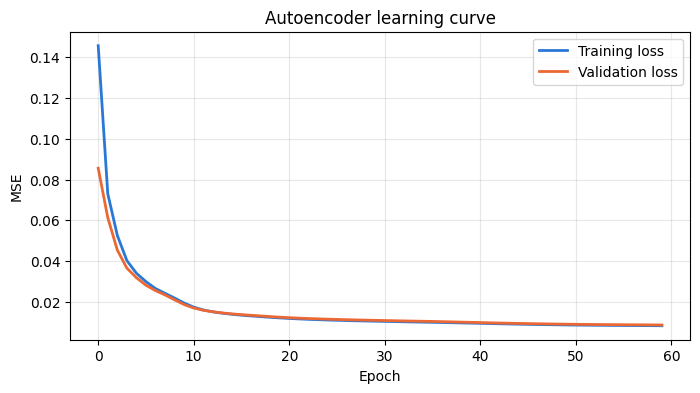

In [12]:
plt.figure(figsize=(8,4))
plt.plot(history.history["loss"], color=color_no, linewidth=2, label="Training loss")
plt.plot(history.history["val_loss"], color=color_yes, linewidth=2, label="Validation loss")
plt.title("Autoencoder learning curve")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Choose the anomaly threshold

A customer is flagged as **yes** when their error is above the threshold.
We try different percentiles of the "no" customers' error on the validation set and keep the one with the best F1-score.

In [13]:
val_errors = reconstruction_error(autoencoder, x_val)
val_errors_no = val_errors[y_val == 0]

percentiles = [50, 60, 70, 75, 80, 85, 90, 95, 99]
threshold_results = []

for p in percentiles:
    threshold = np.percentile(val_errors_no, p)
    val_pred = (val_errors > threshold).astype(int)

    threshold_results.append({
        "percentile": p,
        "threshold": threshold,
        "precision": precision_score(y_val, val_pred),
        "recall": recall_score(y_val, val_pred),
        "f1": f1_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

,percentile,threshold,precision,recall,f1
0,50,0.0008,0.1611,0.7557,0.2655
1,60,0.0018,0.1787,0.6853,0.2835
2,70,0.0161,0.2004,0.5920,0.2994
3,75,0.0163,0.2256,0.5733,0.3237
4,80,0.0167,0.2580,0.5474,0.3507
5,85,0.0176,0.2808,0.4612,0.3491
6,90,0.0248,0.2956,0.3305,0.3121
7,95,0.0334,0.3925,0.2543,0.3086
8,99,0.0606,0.5417,0.0934,0.1593


In [14]:
best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_threshold = best_row["threshold"]

print("Best percentile:", int(best_row["percentile"]))
print("Best threshold:", round(best_threshold, 5))

Best percentile: 80
Best threshold: 0.01667


# Final evaluation on the test set

In [15]:
test_reconstructed = autoencoder.predict(x_test, verbose=0)
test_errors = np.mean((x_test - test_reconstructed) ** 2, axis=1)
test_pred = (test_errors > best_threshold).astype(int)

print("ROC-AUC:  ", round(roc_auc_score(y_test, test_errors), 4))
print("PR-AUC:   ", round(average_precision_score(y_test, test_errors), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall:   ", round(recall_score(y_test, test_pred), 4))
print("F1-score: ", round(f1_score(y_test, test_pred), 4))
print("Random precision (percentage of yes):", round(y_test.mean(), 4))

ROC-AUC:   0.7157
PR-AUC:    0.2879
Precision: 0.2614
Recall:    0.5503
F1-score:  0.3545
Random precision (percentage of yes): 0.1127


In [16]:
cm = confusion_matrix(y_test, test_pred)

pd.DataFrame(
    cm,
    index=["Actual no", "Actual yes"],
    columns=["Predicted no", "Predicted yes"]
)

,Predicted no,Predicted yes
Actual no,4399,1082
Actual yes,313,383


## How useful is the ranking?

If the bank can only call a limited number of customers, it can call those with the **highest error first**.

In [17]:
order = np.argsort(test_errors)[::-1]
sorted_y = y_test[order]

ranking_results = []

for top_percent in [5, 10, 20, 30]:
    n_customers = int(len(y_test) * top_percent / 100)
    yes_found = sorted_y[:n_customers].sum()

    ranking_results.append({
        "called_top_%": top_percent,
        "customers_called": n_customers,
        "yes_found": yes_found,
        "conversion_rate": yes_found / n_customers,
        "share_of_all_yes": yes_found / y_test.sum(),
        "lift_vs_random": (yes_found / n_customers) / y_test.mean()
    })

pd.DataFrame(ranking_results).round(3)

,called_top_%,customers_called,yes_found,conversion_rate,share_of_all_yes,lift_vs_random
0,5,308,142,0.461,0.204,4.092
1,10,617,197,0.319,0.283,2.834
2,20,1235,342,0.277,0.491,2.458
3,30,1853,405,0.219,0.582,1.940


# Error distribution: yes vs no

Median error (no):  0.00072
Median error (yes): 0.01712


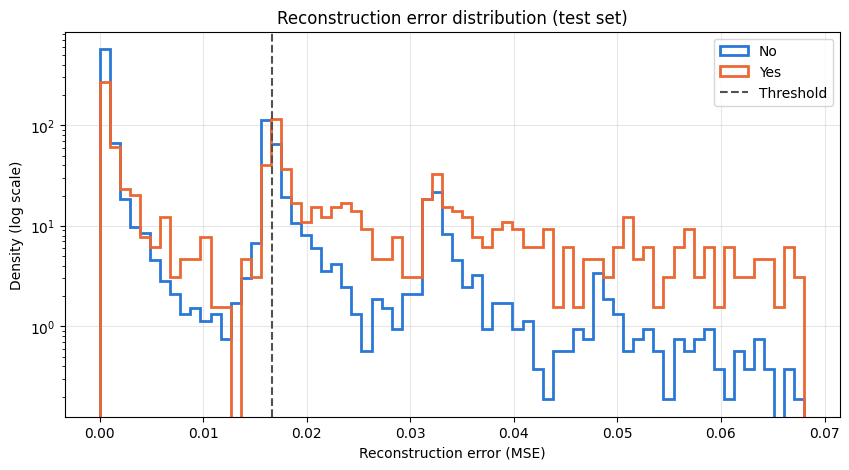

In [18]:
errors_no = test_errors[y_test == 0]
errors_yes = test_errors[y_test == 1]

print("Median error (no): ", round(np.median(errors_no), 5))
print("Median error (yes):", round(np.median(errors_yes), 5))

# Hide the extreme 1% so the main shape is visible
max_error = np.percentile(test_errors, 99)

plt.figure(figsize=(10,5))
plt.hist(errors_no, bins=70, range=(0, max_error), density=True,
         histtype="step", linewidth=2, color=color_no, label="No")
plt.hist(errors_yes, bins=70, range=(0, max_error), density=True,
         histtype="step", linewidth=2, color=color_yes, label="Yes")
plt.axvline(best_threshold, color="#52514e", linestyle="--", linewidth=1.5, label="Threshold")
plt.yscale("log")
plt.title("Reconstruction error distribution (test set)")
plt.xlabel("Reconstruction error (MSE)")
plt.ylabel("Density (log scale)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Per-feature reconstruction error

This shows **which features make "yes" customers look different** from the normal customers the model learned.

In [19]:
feature_errors = (x_test - test_reconstructed) ** 2
error_df = pd.DataFrame(feature_errors, columns=feature_names)

# Combine the one-hot columns back into their original column
original_columns = df.drop(columns=["y"]).columns
column_results = []

for col in original_columns:
    encoded_cols = [c for c in feature_names if c == col or c.startswith(col + "_")]
    column_error = error_df[encoded_cols].sum(axis=1)

    column_results.append({
        "feature": col,
        "No": column_error[y_test == 0].mean(),
        "Yes": column_error[y_test == 1].mean()
    })

column_df = pd.DataFrame(column_results)
column_df["Difference"] = column_df["Yes"] - column_df["No"]
column_df = column_df.sort_values("Difference", ascending=False).reset_index(drop=True)
column_df.round(4)

,feature,No,Yes,Difference
0,month,0.0787,0.4185,0.3397
1,previously_contacted,0.0157,0.1940,0.1783
2,poutcome,0.0157,0.1228,0.1071
3,cons.price.idx,0.0097,0.0605,0.0508
4,job,0.2031,0.2432,0.0401
5,cons.conf.idx,0.0072,0.0366,0.0294
6,contact,0.0068,0.0302,0.0234
7,pdays,0.0020,0.0202,0.0183
8,emp.var.rate,0.0036,0.0189,0.0153
9,nr.employed,0.0050,0.0179,0.0129


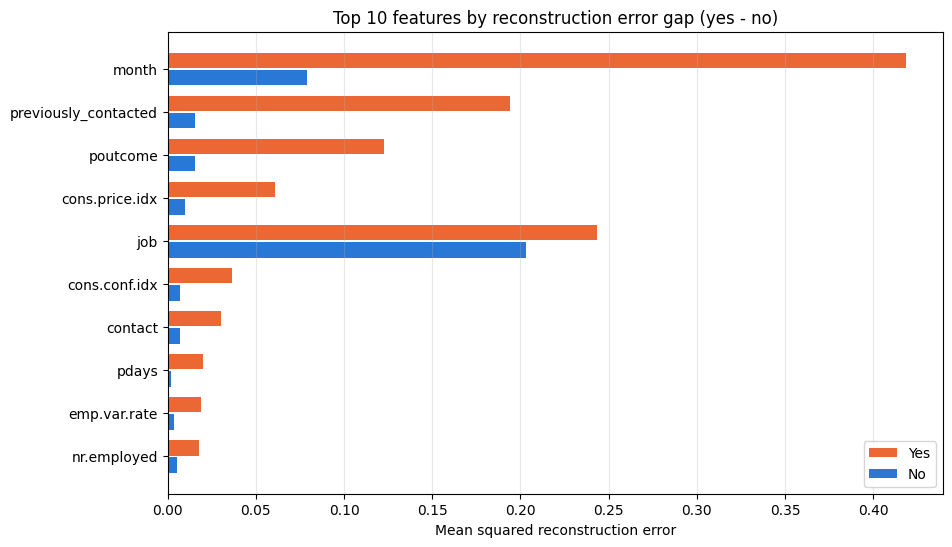

In [20]:
plot_df = column_df.head(10).iloc[::-1]
positions = np.arange(len(plot_df))

plt.figure(figsize=(10,6))
plt.barh(positions + 0.2, plot_df["Yes"], height=0.36, color=color_yes, label="Yes")
plt.barh(positions - 0.2, plot_df["No"], height=0.36, color=color_no, label="No")
plt.yticks(positions, plot_df["feature"])
plt.title("Top 10 features by reconstruction error gap (yes - no)")
plt.xlabel("Mean squared reconstruction error")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.show()

## Top individual categories

In [21]:
encoded_df = pd.DataFrame({
    "No": error_df[y_test == 0].mean(),
    "Yes": error_df[y_test == 1].mean()
})
encoded_df["Difference"] = encoded_df["Yes"] - encoded_df["No"]

encoded_df.sort_values("Difference", ascending=False).head(10).round(4)

,No,Yes,Difference
previously_contacted,0.0157,0.1940,0.1783
month_jun,0.0143,0.0905,0.0762
month_mar,0.0077,0.0704,0.0627
poutcome_success,0.0075,0.0669,0.0594
cons.price.idx,0.0097,0.0605,0.0508
job_retired,0.0343,0.0833,0.0490
month_sep,0.0080,0.0560,0.0480
poutcome_nonexistent,0.0062,0.0516,0.0454
month_oct,0.0050,0.0448,0.0397
month_jul,0.0067,0.0417,0.0350


# Conclusion

**Best model:** 63 → 32 → 16 → 32 → 63, trained on "no" customers only. A deeper network did not improve the results, and the differences between the tuned models were small.

**Test results:**

| Metric | Result |
|---|---|
| ROC-AUC | 0.716 |
| PR-AUC | 0.288 (random = 0.113) |
| Precision | 26.1% (random = 11.3%) |
| Recall | 55.0% |
| F1-score | 0.355 |

**Error distribution:** the median error of "yes" customers (0.0171) is much higher than "no" customers (0.0007). The two groups still overlap, because many "yes" customers look like normal customers.

**Ranking customers:** calling the top 5% by error gives a 46.1% conversion rate, about **4.1x better than random**. Calling the top 20% finds **49.1% of all "yes" customers**.

**Per-feature error:** `month`, `previously_contacted` and `poutcome` show the biggest gap between yes and no. `job` has a high error for both groups, so it does not separate them well.

**Limitation:** "yes" customers are not always unusual, so the autoencoder works best as a way to **rank customers for calling**, and it does not see any "yes" examples during training.

*Exact numbers can change slightly on a different machine or in Colab.*